<a href="https://colab.research.google.com/github/ML-HW-SYS/a2-AaronGoldblatt/blob/main/6_pruning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **6. Model Pruning**

## 6.0 Setup GDrive and Git

In [1]:
# Mount google drive
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [2]:
# Make sure your token is stored in a txt file at the location below.
# This way there is no risk that you will push it to your repo
# Never share your token with anyone, it is basically your github password!
with open('/content/gdrive/MyDrive/ece5545/token.txt') as f:
    token = f.readline().strip()
# Use another file to store your github username
with open('/content/gdrive/MyDrive/ece5545/git_username.txt') as f:
    handle = f.readline().strip()

In [3]:
# Clone your github repo
YOUR_TOKEN = token
YOUR_HANDLE = handle
BRANCH = "main"

%mkdir /content/gdrive/MyDrive/ece5545
%cd /content/gdrive/MyDrive/ece5545
!git clone https://{YOUR_TOKEN}@github.com/ML-HW-SYS/a2-{YOUR_HANDLE}.git
%cd /content/gdrive/MyDrive/ece5545/a2-{YOUR_HANDLE}
!git checkout {BRANCH}
!git pull
%cd /content/gdrive/MyDrive/ece5545

PROJECT_ROOT = f"/content/gdrive/MyDrive/ece5545/a2-{YOUR_HANDLE}"

mkdir: cannot create directory ‘/content/gdrive/MyDrive/ece5545’: File exists
/content/gdrive/MyDrive/ece5545
fatal: destination path 'a2-AaronGoldblatt' already exists and is not an empty directory.
/content/gdrive/MyDrive/ece5545/a2-AaronGoldblatt
Already on 'main'
Your branch is up to date with 'origin/main'.
remote: Enumerating objects: 3, done.
remote: Counting objects: 100% (1/1), done.
remote: Total 3 (delta 1), reused 1 (delta 1), pack-reused 2 (from 1)
Unpacking objects: 100% (3/3), 105.85 KiB | 1.73 MiB/s, done.
From https://github.com/ML-HW-SYS/a2-AaronGoldblatt
   368484b..d6f90d1  main       -> origin/main
Updating 368484b..d6f90d1
Fast-forward
 4_model_conversion_structured_pruned.ipynb | 14526 +++++++++++++++--------------------------------
 1 file changed, 4536 insertions(+), 9990 deletions(-)
/content/gdrive/MyDrive/ece5545


In [4]:
# This extension reloads all imports before running each cell
%load_ext autoreload
%autoreload 2

### GPU: Ensure you are running the GPU runtime type:
1.   Click "Runtime" on top banner
2.   Select "Change runtime type"
3.   Under "Hardware accelarator" select "GPU" and save

### Install required packages

In [5]:
!pip install torchaudio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 76.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 60.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 45.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 89.3 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling nvidia-nvjitlink-cu12-12.5.82:
      Successfully uninstalled nvidia-nvjitlin

### Import code dependencies

In [6]:
# Import libraries
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.nn.utils.prune as prune

import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import numpy as np
import copy

import time

import sys

# Adding assignment1 to the system path-- make sure this matches your git directory
sys.path.insert(0, PROJECT_ROOT)

# Import data_proc to use data processing functions
import src.data_proc as data_proc

# Import constants to use constants defined for training
from src.constants import *

# TensorBoard
from torch.utils.tensorboard import SummaryWriter

# Set random seed
# Make sure the shuffling and picking is deterministic
# Note that different value of random_seed may change rate of variation in loss/accuracy during training
# Using the same random seed value every time you rerun the notebook will
# reproduce the training and testing results
random_seed = 0
torch.manual_seed(random_seed)
torch.cuda.manual_seed(random_seed)

Model folders are created, 
PyTorch models will be saved in /content/gdrive/MyDrive/ece5545/models/torch_models, 
ONNX models will be saved in /content/gdrive/MyDrive/ece5545/models/onnx_models, 
TensorFlow Saved Models will be saved in /content/gdrive/MyDrive/ece5545/models/tf_models, 
TensorFlow Lite models will be saved in /content/gdrive/MyDrive/ece5545/models/tflite_models, 
TensorFlow Lite Micro models will be saved in /content/gdrive/MyDrive/ece5545/models/micro_models.


## 6.1 Prepare for Training



In [7]:
# Create audio_processor
# DATASET_DIR is defined in constants.py
audio_processor = data_proc.AudioProcessor()
print("Audio_processor created")

# Define device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f'Using {device} to run the training scrpit.')

# Define data loaders
from src.loaders import make_data_loaders
data_loaders = make_data_loaders(audio_processor, device)
train_loader = data_loaders['training']
test_loader = data_loaders['testing']
valid_loader = data_loaders['validation']

# Create a full precision (float32) TinyConv model
from src.networks import TinyConv, TinyConvPurged
model_fp32 = TinyConv(model_settings=audio_processor.model_settings, \
    n_input=1, n_output=audio_processor.num_labels)

model_fp32

>> Downloading speech_commands_v0.02.tar.gz 100.0%
Audio_processor created
Using cuda to run the training scrpit.
Train size: 10556 Val size: 1333 Test size: 1368


TinyConv(
  (conv_reshape): Reshape(output_shape=(-1, 1, 49, 40))
  (conv): Conv2d(1, 8, kernel_size=(10, 8), stride=(2, 2), padding=(5, 3))
  (relu): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
  (fc_reshape): Reshape(output_shape=(-1, 4000))
  (fc): Linear(in_features=4000, out_features=4, bias=True)
  (softmax): Softmax(dim=1)
)

In [ ]:
!ls {TORCH_DIR}

 finetuned_structured_pruning_model_threshold_0.25.pt
 finetuned_structured_pruning_model_threshold_0.45.pt
 finetuned_structured_pruning_model_threshold_0.6.pt
 finetuned_structured_pruning_model_threshold_0.75.pt
 finetuned_structured_pruning_model_threshold_0.85.pt
 finetuned_structured_pruning_model_threshold_0.95.pt
 finetuned_unstructured_pruning_model_threshold_0.25.pt
 finetuned_unstructured_pruning_model_threshold_0.45.pt
 finetuned_unstructured_pruning_model_threshold_0.6.pt
 finetuned_unstructured_pruning_model_threshold_0.75.pt
 finetuned_unstructured_pruning_model_threshold_0.85.pt
 finetuned_unstructured_pruning_model_threshold_0.95.pt
 fp32_checkpoint.pt
 fp32_checkpoint.pt.old
 fp32_finetune_checkpoint.pt
 fp32_finetune_checkpoint.pt.old
'(QAT4bit)quant_0.pt'
 quant_checkpoint.pt
 quant_checkpoint.pt.old
 tinyconv_float32_init_seed0_92.25%_0.pt


### **TODO: Replace the torch_path model with the model you created in the last section.**

You can find the name of your file in `TORCH_DIR` under the folder icon to the left. (Or from running the tab above).

In [ ]:
# TODO: Replace me!
torch_path = os.path.join(TORCH_DIR, "tinyconv_float32_init_seed0_92.25%_0.pt")

# Load model
model_fp32.load_state_dict(torch.load(torch_path))
model_fp32_orig = copy.deepcopy(model_fp32)
model_fp32, model_fp32_orig

<ipython-input-160-d99b6118d8e5>:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_fp32.load_state_dict(torch.load(torch_path))


(TinyConv(
   (conv_reshape): Reshape(output_shape=(-1, 1, 49, 40))
   (conv): Conv2d(1, 8, kernel_size=(10, 8), stride=(2, 2), padding=(5, 3))
   (relu): ReLU()
   (dropout): Dropout(p=0.5, inplace=False)
   (fc_reshape): Reshape(output_shape=(-1, 4000))
   (fc): Linear(in_features=4000, out_features=4, bias=True)
   (softmax): Softmax(dim=1)
 ),
 TinyConv(
   (conv_reshape): Reshape(output_shape=(-1, 1, 49, 40))
   (conv): Conv2d(1, 8, kernel_size=(10, 8), stride=(2, 2), padding=(5, 3))
   (relu): ReLU()
   (dropout): Dropout(p=0.5, inplace=False)
   (fc_reshape): Reshape(output_shape=(-1, 4000))
   (fc): Linear(in_features=4000, out_features=4, bias=True)
   (softmax): Softmax(dim=1)
 ))

In [9]:
pruning_thresholds = [
    0.25,
    0.45,
    0.6,
    0.75,
    0.85,
    0.95,
]

## 6.2 Structured Pruning

In this section, you will try to conduct structured pruning on the TinyConv model and explore its effect on performance.
In this notebook, you will be only given minimum scarfolding code. Please take advantages of the code in previous section to faciliate.

Following link will be helpful:
[torch.nn.utils.prune.LnStructured](https://pytorch.org/docs/stable/generated/torch.nn.utils.prune.LnStructured.html?highlight=prune#torch.nn.utils.prune.LnStructured.prune)
[Torch pruning tutorial](https://pytorch.org/tutorials/intermediate/pruning_tutorial.html?highlight=prune)

In [ ]:
def structured_pruning(model, threshold, norm_type=1):
    pruned_model = copy.deepcopy(model)
    for name, module in pruned_model.named_modules():
        if isinstance(module, nn.Conv2d):
            prune.ln_structured(module, name="weight", n=norm_type, amount=threshold, dim=0)
            # prune.remove(module, "weight")
        elif isinstance(module, nn.Linear):
            # Use dim=1 to prune only input connections to ensure that network doesn't become disconnected and that an output class isn't removed
            prune.ln_structured(module, name="weight", n=norm_type, amount=threshold, dim=1)
            # prune.remove(module, "weight")
    return pruned_model

In [ ]:
# from src.networks import TinyConvPurged

# def purge_pruned_channels(original_model, pruned_model, device='cuda'):
#     original_model = original_model.to(device)
#     pruned_model = pruned_model.to(device)

#     conv_mask = pruned_model.conv.weight_mask
#     remaining_conv_channels = torch.sum(conv_mask, dim=(1,2,3)) > 0
#     num_conv_channels = int(remaining_conv_channels.sum())

#     linear_mask = pruned_model.fc.weight_mask
#     remaining_linear_inputs = torch.sum(linear_mask, dim=0) > 0
#     num_linear_inputs = int(remaining_linear_inputs.sum())

#     new_model = TinyConvPurged(
#         model_settings=original_model.model_settings,
#         n_input=1,
#         n_output=original_model.fc.out_features,
#         num_filters=num_conv_channels
#     ).to(device)

#     with torch.no_grad():
#         new_model.conv.weight.data = original_model.conv.weight.data[remaining_conv_channels].clone()
#         new_model.conv.bias.data = original_model.conv.bias.data[remaining_conv_channels].clone()

#         new_model.fc.weight.data = original_model.fc.weight.data[:, remaining_linear_inputs].clone()
#         new_model.fc.bias.data = original_model.fc.bias.data.clone()

#     return new_model


In [ ]:
from src.networks import TinyConvPurged

def purge_pruned_channels(original_model, pruned_model, device='cuda'):
    original_model = original_model.to(device)
    pruned_model = pruned_model.to(device)

    # Get the conv layer mask and find any channels with non-zero values remaining, turn that into a bool mask
    conv_mask = pruned_model.conv.weight_mask
    remaining_conv_channels = torch.sum(conv_mask, dim=(1,2,3)) > 0

    # Because clipping channels and making network denser, need to be sure at least one channel remains or model won't work
    if not torch.any(remaining_conv_channels):
        # Keep the channel with the highest L1 norm (for keeping sparse tensors with key features) if pruning was too aggressive and no channels remain
        channel_norms = torch.norm(original_model.conv.weight.data, p=1, dim=(1,2,3))
        max_norm_idx = torch.argmax(channel_norms)
        remaining_conv_channels[max_norm_idx] = True

    num_conv_channels = int(remaining_conv_channels.sum())

    # Get original full model dimensions from conv layer and all relevant dimensions to convolutions
    original_conv_out_channels = original_model.conv.weight.shape[0]
    original_conv_kernel = original_model.conv.weight.shape[2:4]
    original_conv_stride = original_model.conv.stride
    original_conv_padding = original_model.conv.padding

    # Calculate output dimensions
    H = original_model.model_settings['spectrogram_length']
    W = original_model.model_settings['fingerprint_width']
    out_h = ((H + 2 * original_conv_padding[0] - original_conv_kernel[0]) // original_conv_stride[0] + 1)
    out_w = ((W + 2 * original_conv_padding[1] - original_conv_kernel[1]) // original_conv_stride[1] + 1)

    # Create new purged model with correct number of filters post-pruning
    new_model = TinyConvPurged(
        model_settings=original_model.model_settings,
        n_input=1,
        n_output=original_model.fc.out_features,
        num_filters=num_conv_channels
    ).to(device)

    # Copy weights over for remaining channels in conv layer, using the bitmask from before, disabling gradients for efficiency
    with torch.no_grad():
        new_model.conv.weight.data = original_model.conv.weight.data[remaining_conv_channels].clone()
        new_model.conv.bias.data = original_model.conv.bias.data[remaining_conv_channels].clone()

        # Adjust the linear layer's input size based on remaining conv channels, as its input comes from conv layer's output thus even though both were pruned, they need to match
        new_fc_in_features = num_conv_channels * out_h * out_w
        new_model.fc = nn.Linear(new_fc_in_features, original_model.fc.out_features).to(device)

        # Reshape the FC weights to match the new input size to ensure everything flows properly and all tensors are compatible
        old_fc_weights = original_model.fc.weight.data
        old_fc_bias = original_model.fc.bias.data

        # Initialize the new FC layer with the weights corresponding to remaining channels, removing anything that was pruned and miantaining appropriate connections to preserve learning
        reshaped_weights = old_fc_weights.view(-1, original_conv_out_channels, out_h * out_w)
        reshaped_weights = reshaped_weights[:, remaining_conv_channels, :]
        new_model.fc.weight.data = reshaped_weights.reshape(original_model.fc.out_features, -1)
        new_model.fc.bias.data = old_fc_bias.clone()

    return new_model

In [10]:
structured_pruning_results = {
    'pruned_models': [],
    'finetuned_pruned_models': [],
    'thresholds': [],
    'num_params': [],
    'flops': [],
    'base_accs': [],
    'finetuned_accs': [],
    'cpu_runtimes': [],
    'mcu_runtimes': [],
}

In [ ]:
def count_nonzero_params(model):
    conv_params = (
        model.conv.weight.nelement()
        - torch.sum(model.conv.weight == 0)
        + model.conv.bias.nelement()
    )
    linear_params = (
        model.fc.weight.nelement()
        - torch.sum(model.fc.weight == 0)
        + model.fc.bias.nelement()
    )
    return float(conv_params + linear_params)

In [ ]:
# def flop_pruned(model, input_shape, device):
#     total = {}

#     def count_flops(name):
#         def hook(module, input, output):
#             flops = {}
#             batch_size = input[0].shape[0]

#             if isinstance(module, nn.Linear):
#                 non_zero_weights = torch.nonzero(module.weight.data)
#                 input_features = non_zero_weights.size(0) // module.out_features
#                 output_features = output.shape[1]
#                 flops['multiply'] = batch_size * input_features * output_features
#                 flops['add'] = batch_size * input_features * output_features
#                 if module.bias is not None:
#                     flops['add'] += batch_size * output_features

#             if isinstance(module, nn.Conv2d):
#                 non_zero_channels = torch.nonzero(module.weight.data.sum(dim=(2, 3))).size(0) // module.out_channels
#                 out_channels = output.shape[1]
#                 output_height, output_width = output.shape[2:]
#                 kernel_operations = module.kernel_size[0] * module.kernel_size[1] * (non_zero_channels // module.groups)
#                 flops['multiply'] = batch_size * output_height * output_width * out_channels * kernel_operations
#                 flops['add'] = batch_size * output_height * output_width * out_channels * kernel_operations
#                 if module.bias is not None:
#                     flops['add'] += batch_size * out_channels * output_height * output_width

#             if isinstance(module, (nn.BatchNorm1d, nn.BatchNorm2d)):
#                 num_elements = np.prod(input[0].shape)
#                 flops['add'] = num_elements * 2
#                 flops['multiply'] = num_elements * 2

#             total[name] = flops
#         return hook

#     handle_list = []
#     for name, module in model.named_modules():
#         handle = module.register_forward_hook(count_flops(name))
#         handle_list.append(handle)
#     input = torch.ones(input_shape).to(device)
#     model(input)

#     # Remove forward hooks
#     for handle in handle_list:
#         handle.remove()
#     return total

In [ ]:
from src.size_estimate import flop, count_trainable_parameters
from src.train_val_test_utils import test

for threshold in pruning_thresholds:
    structured_pruning_results['thresholds'].append(threshold)
    print(f'Pruning model with threshold {threshold}')
    original_params = count_trainable_parameters(model_fp32)
    model_fp32.to(device)
    original_flop_by_layers = flop(
        model=model_fp32,
        input_shape=(
            1,
            model_fp32.model_settings['fingerprint_width'],
            model_fp32.model_settings['spectrogram_length']
        ),
        device=device
    )
    original_total_flops = sum([sum(val.values()) for val in original_flop_by_layers.values()])

    pruned_model = structured_pruning(model_fp32, threshold)
    pruned_model = purge_pruned_channels(model_fp32_orig, pruned_model, device)
    structured_pruning_results['pruned_models'].append(pruned_model)
    pruned_model.to(device)

    # num_params = count_nonzero_params(pruned_model)
    num_params = count_trainable_parameters(pruned_model)
    structured_pruning_results['num_params'].append(num_params)
    print(f"Original parameters: {original_params}, Pruned parameters: {num_params}")

    flop_by_layers = flop(
        model=pruned_model,
        input_shape=(
            1,
            model_fp32.model_settings['fingerprint_width'],
            model_fp32.model_settings['spectrogram_length']
        ),
        device=device
    )
    total_param_flops = sum([sum(val.values()) for val in flop_by_layers.values()])
    structured_pruning_results['flops'].append(total_param_flops)
    print(f"Original FLOPs: {original_total_flops}, Pruned FLOPs: {total_param_flops}")

    base_acc = test(
        test_loader,
        pruned_model,
        device,
        loader_type='Test'
    )
    structured_pruning_results['base_accs'].append(base_acc)
    print(f'Base Accuracy: {base_acc}')

    print()

Pruning model with threshold 0.25
Original parameters: 16652, Pruned parameters: 12490
Original FLOPs: 676004, Pruned FLOPs: 507004
Base Accuracy: 79.67836257309942

Pruning model with threshold 0.45
Original parameters: 16652, Pruned parameters: 8328
Original FLOPs: 676004, Pruned FLOPs: 338004
Base Accuracy: 78.21637426900585

Pruning model with threshold 0.6
Original parameters: 16652, Pruned parameters: 6247
Original FLOPs: 676004, Pruned FLOPs: 253504
Base Accuracy: 65.8625730994152

Pruning model with threshold 0.75
Original parameters: 16652, Pruned parameters: 4166
Original FLOPs: 676004, Pruned FLOPs: 169004
Base Accuracy: 62.134502923976605

Pruning model with threshold 0.85
Original parameters: 16652, Pruned parameters: 2085
Original FLOPs: 676004, Pruned FLOPs: 84504
Base Accuracy: 52.99707602339181

Pruning model with threshold 0.95
Original parameters: 16652, Pruned parameters: 2085
Original FLOPs: 676004, Pruned FLOPs: 84504
Base Accuracy: 53.50877192982456



In [ ]:
def plot_accuracy_vs_parameters(results, acc_type='base_accs', pruning_type='Structured', save_path=None):
    """
    Plot accuracy vs parameters for pruning results.

    Args:
        results: Dictionary containing 'params', 'thresholds', and either 'base_accs' or 'finetuned_accs'
        acc_type: String indicating which accuracy to plot ('base_accs' or 'finetuned_accs')
        pruning_type: String indicating type of pruning ('Structured' or 'Unstructured')
        save_path: Optional path to save the plot (e.g., 'accuracy_vs_params.png')
    """
    plt.figure(figsize=(10, 6))

    # Select correct accuracy data and title suffix
    if acc_type == 'base_accs':
        acc_data = results['base_accs']
        title_suffix = 'without Fine-tuning'
        color = 'blue'
    elif acc_type == 'finetuned_accs':
        acc_data = results['finetuned_accs']
        title_suffix = 'with Fine-tuning'
        color = 'red'
    else:
        raise ValueError(f"Invalid accuracy type: {acc_type}")

    # Plot accuracy vs parameters
    plt.plot(results['num_params'],
         acc_data,
         'o--',  # Only specify marker and line style here
         color=color,  # Specify color separately
         linewidth=2,
         markersize=8)

    # Add threshold labels to points
    for i, (param, acc, threshold) in enumerate(zip(results['num_params'],
                                                   acc_data,
                                                   results['thresholds'])):
        plt.annotate(f'{threshold:.2f}',  # threshold value with 1 decimal
                    (param, acc),
                    xytext=(10, 10),      # offset from point
                    textcoords='offset points',
                    fontsize=10,
                    bbox=dict(facecolor='white', edgecolor='none', alpha=0.7))

    # Add labels and title
    plt.xlabel('Number of Parameters', fontsize=12)
    plt.ylabel('Accuracy (%)', fontsize=12)
    plt.title(f'Accuracy vs. Number of Parameters ({pruning_type} Pruning, {title_suffix})', fontsize=14)

    # Add grid
    plt.grid(True, linestyle='--', alpha=0.7)

    # Adjust layout to prevent label cutoff
    plt.tight_layout()

    # Save if path provided
    if save_path:
        plt.savefig(save_path)

    plt.show()

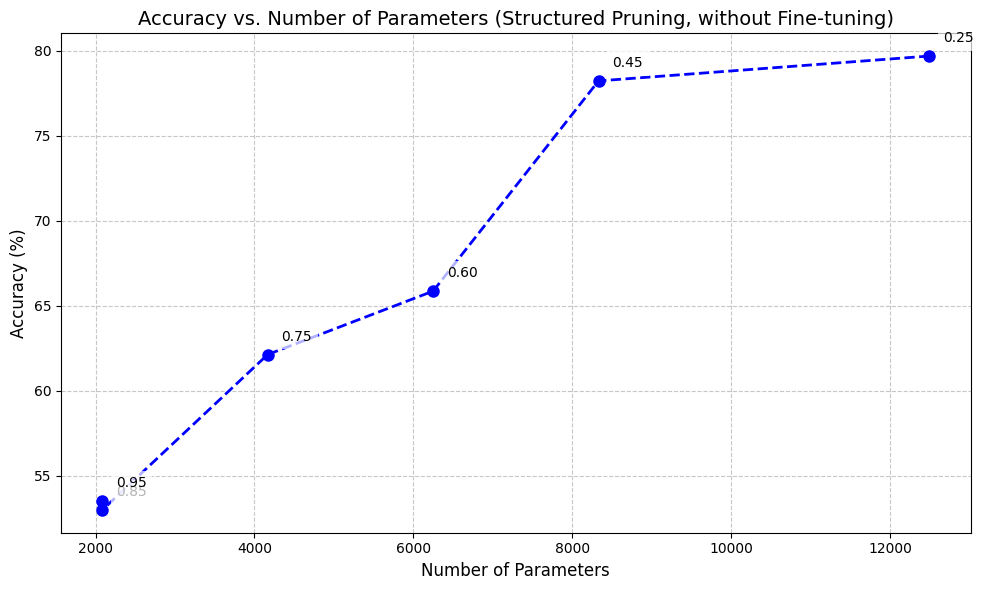

In [ ]:
plot_accuracy_vs_parameters(
    structured_pruning_results,
    acc_type='base_accs',
    pruning_type='Structured'
)

In [ ]:
def plot_accuracy_vs_flops(results, acc_type='base_accs', save_path=None):
    """
    Plot accuracy vs FLOPs for structured pruning results.

    Args:
        results: Dictionary containing 'flops', 'thresholds', and either 'base_accs' or 'finetuned_accs'
        acc_type: String indicating which accuracy to plot ('base_accs' or 'finetuned_accs')
        save_path: Optional path to save the plot
    """
    plt.figure(figsize=(10, 6))

    # Select correct accuracy data and title suffix
    if acc_type == 'base_accs':
        acc_data = results['base_accs']
        title_suffix = 'without Fine-tuning'
        color = 'blue'
    elif acc_type == 'finetuned_accs':
        acc_data = results['finetuned_accs']
        title_suffix = 'with Fine-tuning'
        color = 'red'
    else:
        raise ValueError(f"Invalid accuracy type: {acc_type}")

    # Plot accuracy vs FLOPs
    plt.plot(results['flops'],
             acc_data,
             'o--',
             color=color,
             linewidth=2,
             markersize=8)

    # Add threshold labels to points
    for i, (flop, acc, threshold) in enumerate(zip(results['flops'],
                                                  acc_data,
                                                  results['thresholds'])):
        plt.annotate(f'{threshold:.2f}',
                    (flop, acc),
                    xytext=(10, 10),
                    textcoords='offset points',
                    fontsize=10,
                    bbox=dict(facecolor='white', edgecolor='none', alpha=0.7))

    # Add labels and title
    plt.xlabel('FLOPs', fontsize=12)
    plt.ylabel('Accuracy (%)', fontsize=12)
    plt.title(f'Accuracy vs. FLOPs (Structured Pruning, {title_suffix})', fontsize=14)

    # Add grid
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path)

    plt.show()

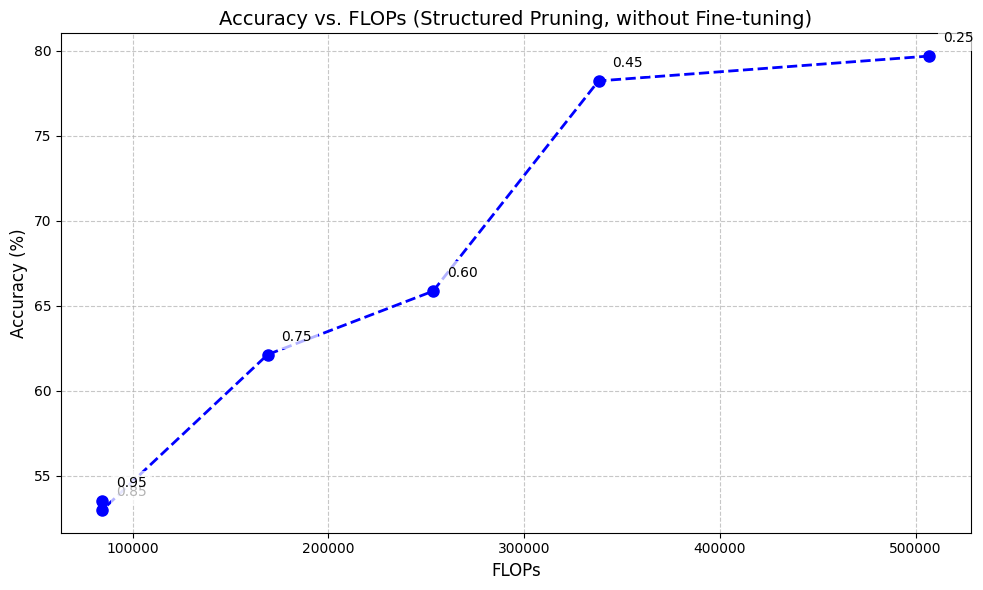

In [ ]:
plot_accuracy_vs_flops(
    structured_pruning_results,
    acc_type='base_accs',
)

In [ ]:
from src.train_val_test_utils import create_optimizer, train, test

def fine_tune(model, device, epochs=10, learning_rate=0.001):
    optimizer = create_optimizer(model, learning_rate=learning_rate)
    best_acc = 0
    best_model = None
    for epoch in range(1, epochs + 1):
        train(
            model,
            data_loaders,
            optimizer,
            epoch,
            device
        )
        val_acc = test(
            valid_loader,
            model,
            device,
            epoch=epoch,
            loader_type='Valid'
        )
        if val_acc > best_acc:
            best_acc = val_acc
            best_model = copy.deepcopy(model.state_dict())
    if best_model is not None:
        model.load_state_dict(best_model)
    test_acc = test(
        test_loader,
        model,
        device,
        loader_type='Test'
    )
    return model, test_acc

In [ ]:
for idx, model in enumerate(structured_pruning_results['pruned_models']):
    print(f"Fine-tuning model with threshold {structured_pruning_results['thresholds'][idx]}")
    finetuned_model, finetuned_acc = fine_tune(model, device)
    structured_pruning_results['finetuned_pruned_models'].append(finetuned_model)
    structured_pruning_results['finetuned_accs'].append(finetuned_acc)
    print()

Fine-tuning model with threshold 0.25
Val Acc Epoch 1 = 87.7%, Train loss = 0.467
Val Acc Epoch 2 = 87.4%, Train loss = 0.429
Val Acc Epoch 3 = 89.27%, Train loss = 0.409
Val Acc Epoch 4 = 89.5%, Train loss = 0.415
Val Acc Epoch 5 = 88.45%, Train loss = 0.406
Val Acc Epoch 6 = 88.9%, Train loss = 0.404
Val Acc Epoch 7 = 88.3%, Train loss = 0.403
Val Acc Epoch 8 = 89.2%, Train loss = 0.39
Val Acc Epoch 9 = 88.3%, Train loss = 0.387
Val Acc Epoch 10 = 89.05%, Train loss = 0.386

Fine-tuning model with threshold 0.45
Val Acc Epoch 1 = 86.95%, Train loss = 0.52
Val Acc Epoch 2 = 87.7%, Train loss = 0.459
Val Acc Epoch 3 = 88.22%, Train loss = 0.458
Val Acc Epoch 4 = 88.07%, Train loss = 0.446
Val Acc Epoch 5 = 88.0%, Train loss = 0.445
Val Acc Epoch 6 = 88.3%, Train loss = 0.433
Val Acc Epoch 7 = 88.75%, Train loss = 0.429
Val Acc Epoch 8 = 88.07%, Train loss = 0.44
Val Acc Epoch 9 = 90.02%, Train loss = 0.434
Val Acc Epoch 10 = 89.27%, Train loss = 0.421

Fine-tuning model with threshold 

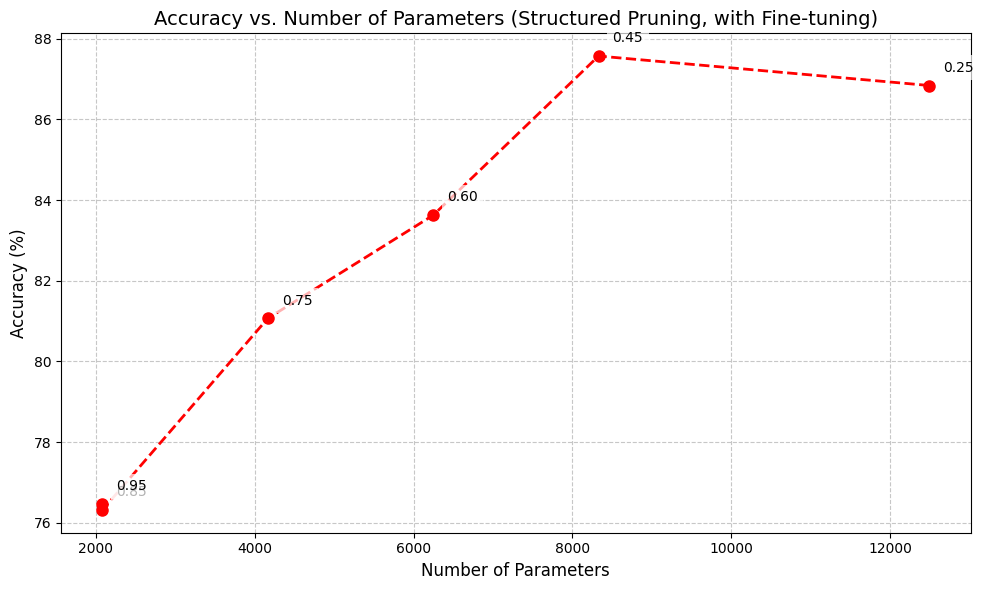

In [ ]:
plot_accuracy_vs_parameters(
    structured_pruning_results,
    acc_type='finetuned_accs',
    pruning_type='Structured'
)

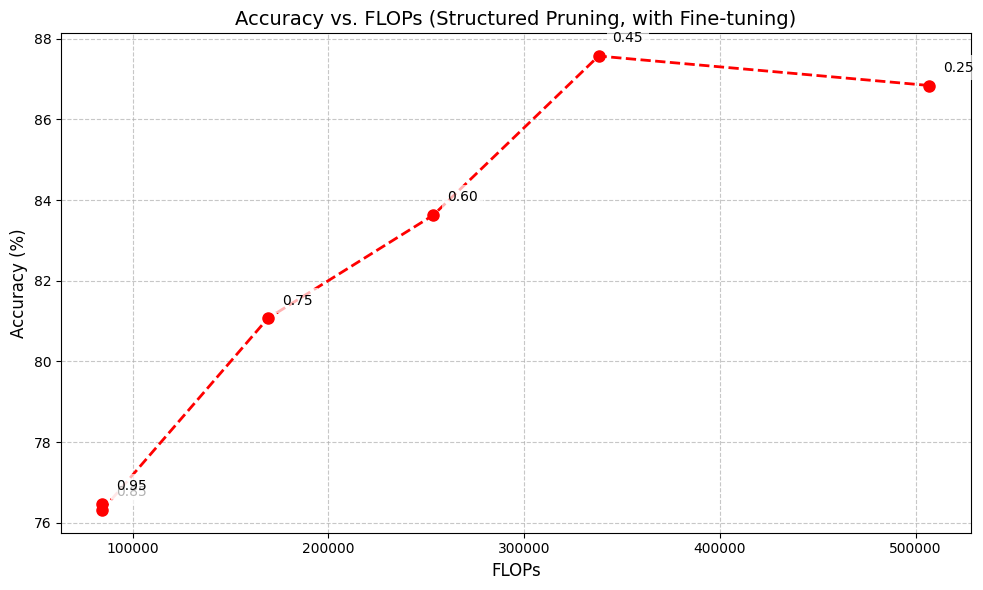

In [ ]:
plot_accuracy_vs_flops(
    structured_pruning_results,
    acc_type='finetuned_accs',
)

In [ ]:
from torch.profiler import profile, record_function, ProfilerActivity

def measure_cpu_runtime(model, num_runs=10, warmup_runs=3):
    model = model.cpu()
    model.eval()
    inputs = torch.rand([1, 1960]).cpu()

    for _ in range(warmup_runs):
        model(inputs)

    total_time = 0
    for _ in range(num_runs):
        with profile(activities=[ProfilerActivity.CPU], record_shapes=True) as prof:
            with record_function("model_inference"):
                model(inputs)
        total_time += prof.key_averages().self_cpu_time_total

    average_time = total_time / num_runs
    # Convert to ms
    return average_time / 1000

In [ ]:
for model in structured_pruning_results['finetuned_pruned_models']:
    cpu_runtime = measure_cpu_runtime(model)
    structured_pruning_results['cpu_runtimes'].append(cpu_runtime)

In [22]:
def plot_accuracy_vs_runtime(results, runtime_type='CPU', save_path=None):
    """
    Plot accuracy vs runtime for structured pruning results.

    Args:
        results: Dictionary containing 'cpu_runtime' or 'mcu_runtime', 'thresholds', and 'finetuned_accs'
        runtime_type: String indicating which runtime to plot ('CPU' or 'MCU')
        save_path: Optional path to save the plot
    """
    plt.figure(figsize=(10, 6))

    # Select correct runtime data
    if runtime_type == 'CPU':
        runtime_data = results['cpu_runtimes']
        xlabel = 'CPU Runtime (ms)'
    elif runtime_type == 'MCU':
        runtime_data = results['mcu_runtimes']
        xlabel = 'MCU Runtime (ms)'
    else:
        raise ValueError(f"Invalid runtime type: {runtime_type}")

    # Plot accuracy vs runtime (always using finetuned accuracy)
    plt.plot(runtime_data,
             results['finetuned_accs'],
             'go',  # red dots with dashed line
             linewidth=2,
             markersize=8)

    # Add threshold labels to points
    for i, (runtime, acc, threshold) in enumerate(zip(runtime_data,
                                                     results['finetuned_accs'],
                                                     results['thresholds'])):
        plt.annotate(f'{threshold:.2f}',
                    (runtime, acc),
                    xytext=(10, 10),
                    textcoords='offset points',
                    fontsize=10,
                    bbox=dict(facecolor='white', edgecolor='none', alpha=0.7))

    # Add labels and title
    plt.xlabel(xlabel, fontsize=12)
    plt.ylabel('Accuracy (%)', fontsize=12)
    plt.title(f'Accuracy vs. {runtime_type} Runtime (Structured Pruning)', fontsize=14)

    # Add grid
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path)

    plt.show()

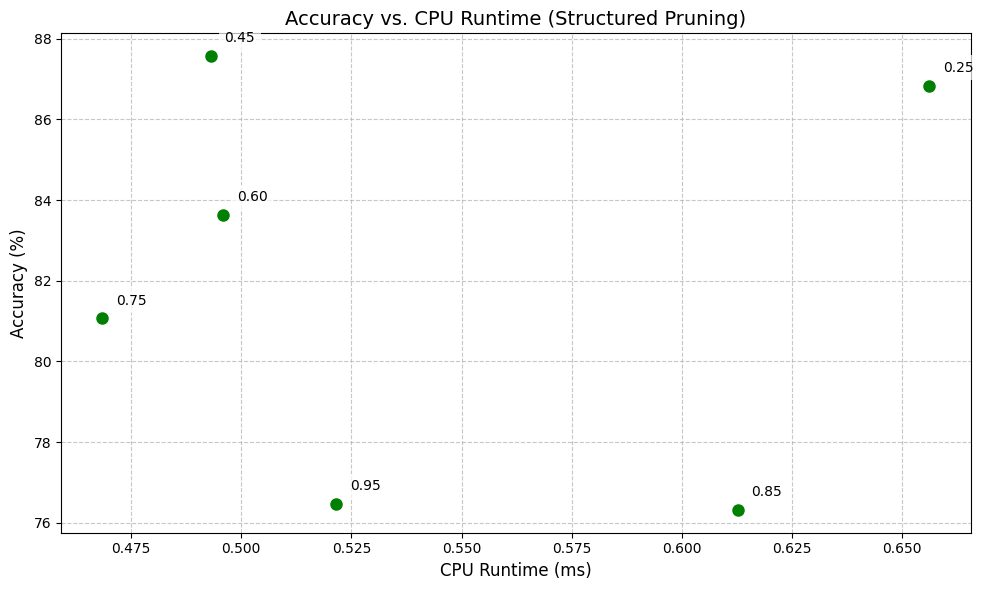

In [ ]:
plot_accuracy_vs_runtime(
    structured_pruning_results,
    runtime_type='CPU'
)

In [ ]:
import os

# Save the finetuned structured pruning models
def save_finetuned_models(results, pruning_type='structured', torch_dir=TORCH_DIR):
    for idx, model in enumerate(results['finetuned_pruned_models']):
        threshold = results['thresholds'][idx]
        model_path = os.path.join(
            torch_dir,
            f'finetuned_{pruning_type}_pruning_model_threshold_{threshold}.pt'
        )
        torch.save(
            model.state_dict(),
            model_path
        )
        print(f"Saved {pruning_type} pruned model with threshold {threshold} to {model_path}")

In [ ]:
save_finetuned_models(structured_pruning_results, pruning_type='structured')

Saved structured pruned model with threshold 0.25 to /content/gdrive/MyDrive/ece5545/models/torch_models/finetuned_structured_pruning_model_threshold_0.25.pt
Saved structured pruned model with threshold 0.45 to /content/gdrive/MyDrive/ece5545/models/torch_models/finetuned_structured_pruning_model_threshold_0.45.pt
Saved structured pruned model with threshold 0.6 to /content/gdrive/MyDrive/ece5545/models/torch_models/finetuned_structured_pruning_model_threshold_0.6.pt
Saved structured pruned model with threshold 0.75 to /content/gdrive/MyDrive/ece5545/models/torch_models/finetuned_structured_pruning_model_threshold_0.75.pt
Saved structured pruned model with threshold 0.85 to /content/gdrive/MyDrive/ece5545/models/torch_models/finetuned_structured_pruning_model_threshold_0.85.pt
Saved structured pruned model with threshold 0.95 to /content/gdrive/MyDrive/ece5545/models/torch_models/finetuned_structured_pruning_model_threshold_0.95.pt


In [19]:
from src.train_val_test_utils import test

# Get back model accuracies from saved model files
for threshold in pruning_thresholds:
    print(f"\nProcessing threshold {threshold}")
    # Construct model path
    model_path = os.path.join(TORCH_DIR, f"finetuned_structured_pruning_model_threshold_{threshold}.pt")

    if not os.path.exists(model_path):
        print(f"Warning: No model found for threshold {threshold}")
        continue

    # Get the number of channels from the saved model
    state_dict = torch.load(model_path)
    num_channels = state_dict['conv.weight'].shape[0]

    # Create the correctly sized TinyConvPurged model
    model = TinyConvPurged(
        model_settings=audio_processor.model_settings,
        n_input=1,
        n_output=audio_processor.num_labels,
        num_filters=num_channels
    )
    model.to(device)

    model.load_state_dict(state_dict)

    model.eval()

    test_acc = test(
        test_loader,
        model,
        device,
        loader_type='Test'
    )

    structured_pruning_results['thresholds'].append(threshold)
    structured_pruning_results['finetuned_accs'].append(test_acc)
    structured_pruning_results['pruned_models'].append(model)


Processing threshold 0.25


<ipython-input-19-92904df745e5>:14: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(model_path)



Processing threshold 0.45

Processing threshold 0.6

Processing threshold 0.75

Processing threshold 0.85

Processing threshold 0.95


In [20]:
# Obtained MCU runtimes by running the 5 finetuned structured pruning models on the MCU
# Using inference runtimes for the plot to match CPU metrics
structured_pruning_results['mcu_runtimes'] = [
    # Threshold 0.25
    80,
    # Threshold 0.45
    72,
    # Threshold 0.6
    68,
    # Threshold 0.75
    64,
    # Threshold 0.85
    60,
    # Threshold 0.95
    60,
]

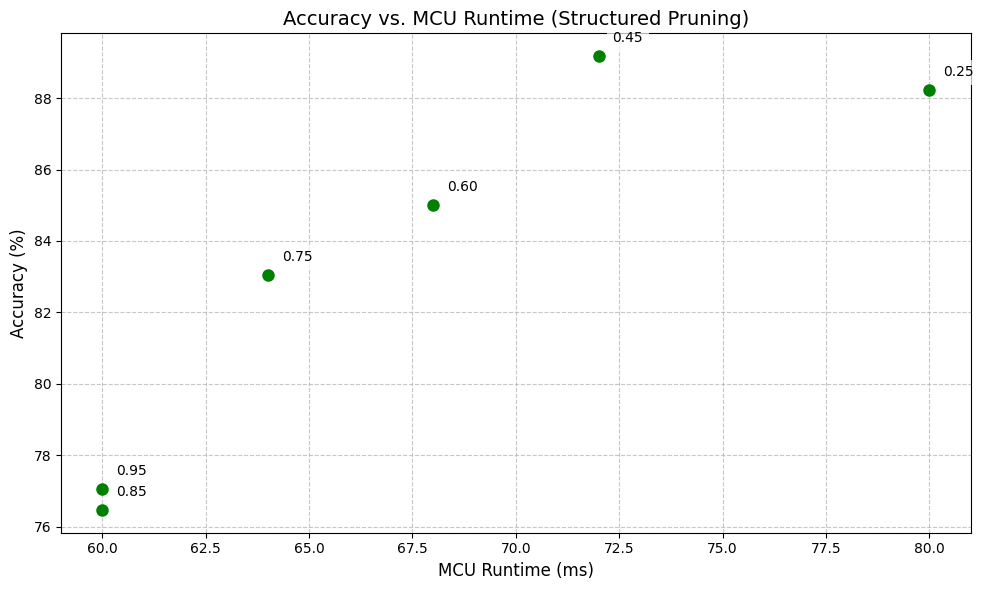

In [23]:
plot_accuracy_vs_runtime(
    structured_pruning_results,
    runtime_type='MCU'
)

## 6.3 Unstructured Pruning

In this section, you will perform unstructured pruning on the TinyConv model and explore its effect on performance.

Following link will be helpful:
1. [torch.nn.utils.prune.l1_unstructured](https://pytorch.org/docs/stable/generated/torch.nn.utils.prune.l1_unstructured.html?highlight=unstructured#torch.nn.utils.prune.l1_unstructured)

2. [torch.nn.utils.prune.random_unstructured](https://pytorch.org/docs/stable/generated/torch.nn.utils.prune.random_unstructured.html?highlight=unstructured#torch.nn.utils.prune.random_unstructured)

2. [Torch pruning tutorial](https://pytorch.org/tutorials/intermediate/pruning_tutorial.html?highlight=prune)

In [ ]:
def unstructured_pruning(model, threshold):
    pruned_model = copy.deepcopy(model)
    for name, module in pruned_model.named_modules():
        if isinstance(module, nn.Conv2d) or isinstance(module, nn.Linear):
            prune.l1_unstructured(module, name='weight', amount=threshold)
            prune.remove(module, 'weight')
    return pruned_model

In [ ]:
unstructured_pruning_results = {
    'pruned_models': [],
    'finetuned_pruned_models': [],
    'thresholds': [],
    'num_params': [],
    'base_accs': [],
    'finetuned_accs': [],
}

In [17]:
from src.train_val_test_utils import test

for threshold in pruning_thresholds:
    unstructured_pruning_results['thresholds'].append(threshold)
    print(f'Pruning model with threshold {threshold}')
    model_fp32.to(device)
    original_params = count_nonzero_params(model_fp32)

    pruned_model = unstructured_pruning(model_fp32, threshold)
    unstructured_pruning_results['pruned_models'].append(pruned_model)
    pruned_model.to(device)

    num_params = count_nonzero_params(pruned_model)
    unstructured_pruning_results['num_params'].append(num_params)
    print(f"Original parameters: {original_params}, Pruned parameters: {num_params}")

    base_acc = test(
        test_loader,
        pruned_model,
        device,
        loader_type='Test'
    )
    unstructured_pruning_results['base_accs'].append(base_acc)
    print(f'Base Accuracy: {base_acc}')

    print()

NameError: name 'unstructured_pruning_results' is not defined

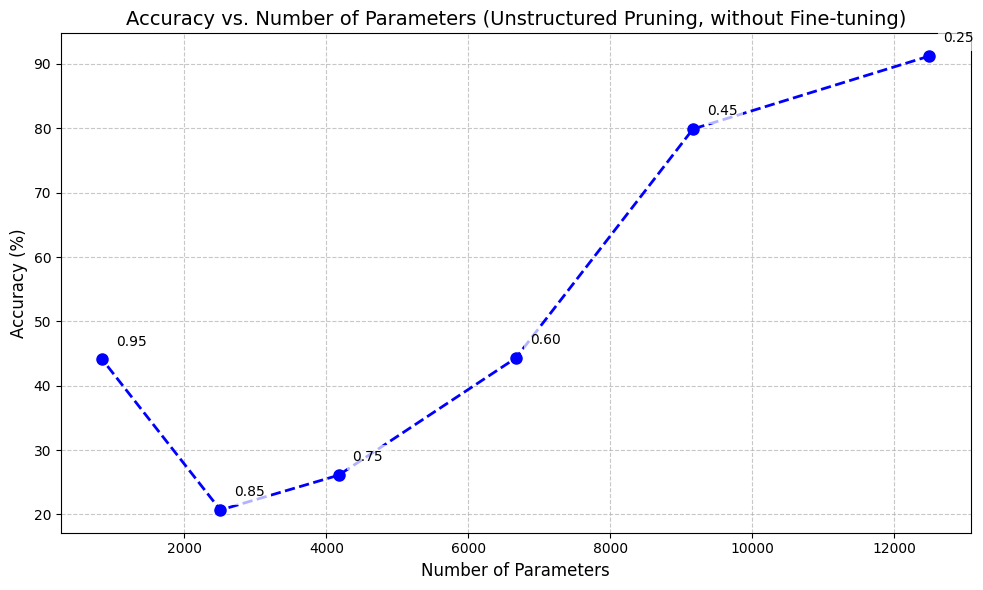

In [ ]:
plot_accuracy_vs_parameters(
    unstructured_pruning_results,
    acc_type='base_accs',
    pruning_type='Unstructured'
)

In [ ]:
for idx, model in enumerate(unstructured_pruning_results['pruned_models']):
    print(f"Fine-tuning model with threshold {structured_pruning_results['thresholds'][idx]}")
    finetuned_model, finetuned_acc = fine_tune(model, device)
    unstructured_pruning_results['finetuned_pruned_models'].append(finetuned_model)
    unstructured_pruning_results['finetuned_accs'].append(finetuned_acc)
    print()

Fine-tuning model with threshold 0.25
Val Acc Epoch 1 = 91.75%, Train loss = 0.323
Val Acc Epoch 2 = 91.6%, Train loss = 0.321
Val Acc Epoch 3 = 90.77%, Train loss = 0.309
Val Acc Epoch 4 = 91.67%, Train loss = 0.321
Val Acc Epoch 5 = 92.27%, Train loss = 0.31
Val Acc Epoch 6 = 91.45%, Train loss = 0.308
Val Acc Epoch 7 = 91.6%, Train loss = 0.318
Val Acc Epoch 8 = 91.9%, Train loss = 0.321
Val Acc Epoch 9 = 91.07%, Train loss = 0.308
Val Acc Epoch 10 = 91.0%, Train loss = 0.303

Fine-tuning model with threshold 0.45
Val Acc Epoch 1 = 91.6%, Train loss = 0.35
Val Acc Epoch 2 = 90.55%, Train loss = 0.322
Val Acc Epoch 3 = 91.97%, Train loss = 0.323
Val Acc Epoch 4 = 91.9%, Train loss = 0.313
Val Acc Epoch 5 = 91.37%, Train loss = 0.32
Val Acc Epoch 6 = 91.45%, Train loss = 0.316
Val Acc Epoch 7 = 90.85%, Train loss = 0.311
Val Acc Epoch 8 = 90.32%, Train loss = 0.321
Val Acc Epoch 9 = 91.75%, Train loss = 0.326
Val Acc Epoch 10 = 90.25%, Train loss = 0.301

Fine-tuning model with thresh

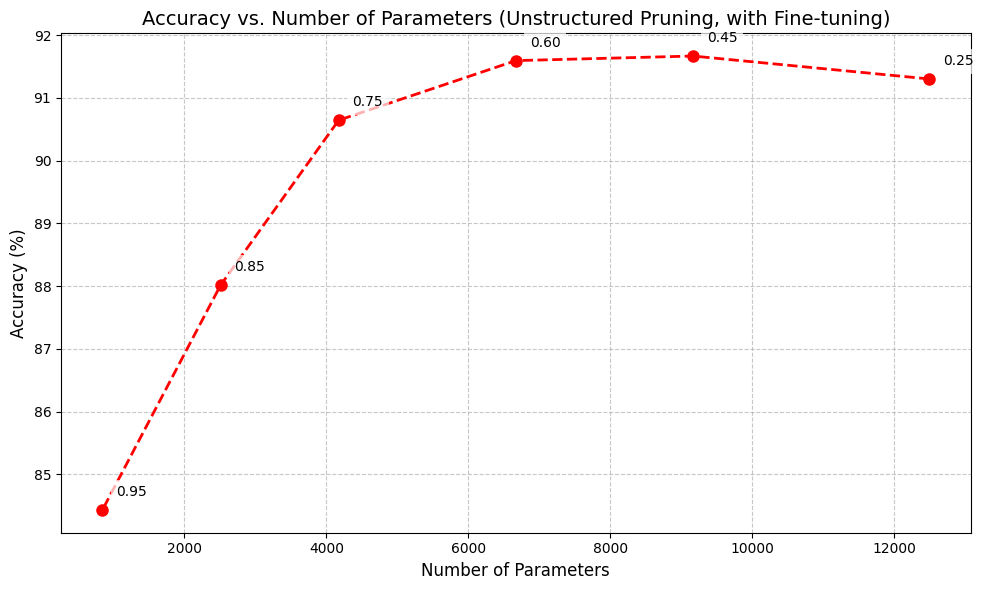

In [ ]:
plot_accuracy_vs_parameters(
    unstructured_pruning_results,
    acc_type='finetuned_accs',
    pruning_type='Unstructured'
)

In [ ]:
save_finetuned_models(unstructured_pruning_results, pruning_type='unstructured')

Saved unstructured pruned model with threshold 0.25 to /content/gdrive/MyDrive/ece5545/models/torch_models/finetuned_unstructured_pruning_model_threshold_0.25.pt
Saved unstructured pruned model with threshold 0.45 to /content/gdrive/MyDrive/ece5545/models/torch_models/finetuned_unstructured_pruning_model_threshold_0.45.pt
Saved unstructured pruned model with threshold 0.6 to /content/gdrive/MyDrive/ece5545/models/torch_models/finetuned_unstructured_pruning_model_threshold_0.6.pt
Saved unstructured pruned model with threshold 0.75 to /content/gdrive/MyDrive/ece5545/models/torch_models/finetuned_unstructured_pruning_model_threshold_0.75.pt
Saved unstructured pruned model with threshold 0.85 to /content/gdrive/MyDrive/ece5545/models/torch_models/finetuned_unstructured_pruning_model_threshold_0.85.pt
Saved unstructured pruned model with threshold 0.95 to /content/gdrive/MyDrive/ece5545/models/torch_models/finetuned_unstructured_pruning_model_threshold_0.95.pt
